# 🏙️ Il costo della vita nelle province italiane

Progetto di **Francesco Autorino** – Data Analyst.

❓ **La domanda**: in quali province si vive meglio con lo stipendio che si guadagna?

Le 5 domande più piccole:

1️⃣ 💶 Dove si guadagna di più e dove di meno?

2️⃣ 🏠 Quanto costano le case nelle province?

3️⃣ ⚖️ Quanti anni di reddito servono per comprare una casa?

4️⃣ 📈 Redditi e prezzi delle case: come sono cambiati dal 2016 al 2024?

5️⃣ ⛽ Quanto pesa un pieno di benzina sul reddito di un mese?

📊 Dati: redditi IRPEF del MEF (2016-2024), prezzi delle case OMI (2016-2025), prezzi dei carburanti MIMIT (ottobre 2026).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

DATI = Path("../02Dati/2Puliti")
GRAFICI = Path("Grafici"); GRAFICI.mkdir(exist_ok=True)
leggi = lambda f: pd.read_csv(DATI / f, keep_default_na=False, na_values=[""])   # "NA" = Napoli!
p = leggi("province.csv")
redditi = leggi("redditi_province.csv")
case = leggi("case_province.csv")
fasce = leggi("fasce_reddito.csv")

# colori del progetto: terracotta, verde petrolio, sabbia, oliva
TERRA, PETROLIO, SABBIA, OLIVA, NOTTE = "#C65D3B", "#1F7A8C", "#E9C46A", "#7A8B3C", "#22333B"
ZONE = {"Nord": PETROLIO, "Centro": OLIVA, "Sud": TERRA, "Isole": SABBIA}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 10})

def salva(nome):
    plt.tight_layout(); plt.savefig(GRAFICI / f"{nome}.png", bbox_inches="tight"); plt.show()

print(f"Province: {len(p)} · anni di redditi: {redditi.anno.min()}-{redditi.anno.max()} · anni di case: {case.anno.min()}-{case.anno.max()}")
p.head()

Province: 107 · anni di redditi: 2016-2024 · anni di case: 2016-2025


,sigla,provincia,regione,zona,latitudine,longitudine,benzina_self,gasolio_self,contribuenti,reddito_medio,...,pensione_media,crescita_reddito_pct,prezzo_casa_mq,crescita_casa_pct,casa_80mq,anni_reddito_casa,pieno_50l,pieno_pct_reddito_mese,indice_costo,posizione
0,AG,Agrigento,Sicilia,Isole,37.3528,13.5845,2.055,2.276,253034,18162.0,...,16787.0,26.2,581.0,-13.0,46480.0,2.6,102.75,6.8,34.0,23.0
1,AL,Alessandria,Piemonte,Nord,44.8955,8.6370,2.023,2.252,311669,25157.0,...,22643.0,18.4,756.0,-13.6,60480.0,2.4,101.15,4.8,15.0,2.0
2,AN,Ancona,Marche,Centro,43.5397,13.3447,2.022,2.238,360370,24788.0,...,22946.0,17.5,1123.0,-10.4,89840.0,3.6,101.10,4.9,44.0,41.0
3,AO,Aosta,Valle d'Aosta,Nord,45.7389,7.3441,2.033,2.262,99839,26873.0,...,23280.0,20.6,1903.0,2.4,152240.0,5.7,101.65,4.5,64.0,74.0
4,AP,Ascoli Piceno,Marche,Centro,42.8966,13.7241,2.037,2.250,155048,23404.0,...,20647.0,26.5,1499.0,7.4,119920.0,5.1,101.85,5.2,71.0,90.0


## 1️⃣ 💶 Dove si guadagna di più?

📌 **Reddito medio** = reddito complessivo dichiarato diviso per il numero di contribuenti con reddito positivo (anno 2024).
È un reddito **lordo**, prima delle tasse.

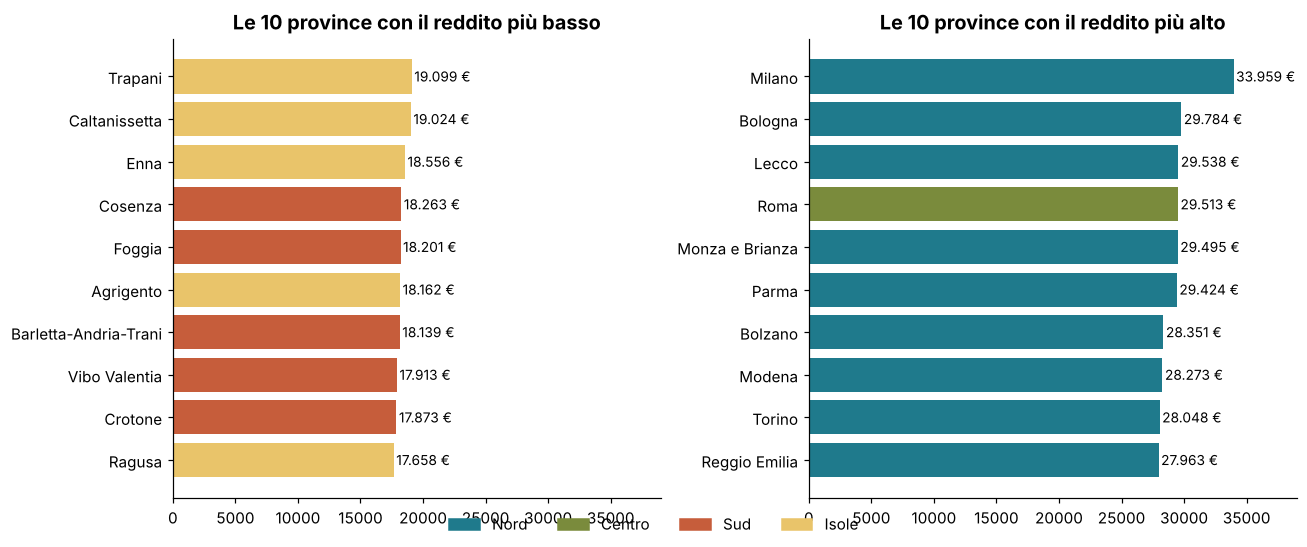

Mediana delle province: 24,470 €
zona
Isole     19585.0
Sud       19892.0
Centro    24270.0
Nord      26366.0
Name: reddito_medio, dtype: float64


In [2]:
o = p.sort_values("reddito_medio")
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for a, d, tit in [(ax[0], o.head(10), "Le 10 province con il reddito più basso"), (ax[1], o.tail(10), "Le 10 province con il reddito più alto")]:
    a.barh(d["provincia"], d["reddito_medio"], color=[ZONE[z] for z in d["zona"]])
    for y, v in enumerate(d["reddito_medio"]): a.text(v + 200, y, f"{v:,.0f} €".replace(",", "."), va="center", fontsize=9)
    a.set_title(tit); a.set_xlim(0, 39000)
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ZONE.values()], labels=list(ZONE), loc="lower center", ncol=4, frameon=False)
plt.subplots_adjust(bottom=0.15); salva("01_reddito_province")
print("Mediana delle province:", f"{p.reddito_medio.median():,.0f} €")
print(p.groupby("zona").reddito_medio.median().round(0).sort_values())

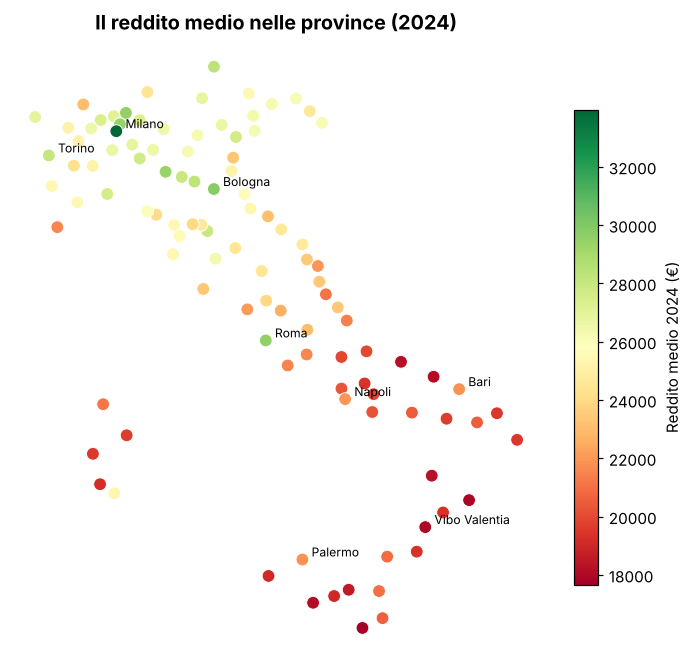

In [3]:
# l'Italia disegnata con un pallino per provincia, colorato per reddito
fig, ax = plt.subplots(figsize=(6.5, 7.5))
s = ax.scatter(p["longitudine"], p["latitudine"], c=p["reddito_medio"], cmap="RdYlGn", s=70, edgecolor="white", linewidth=0.6)
for sig in ["MI", "RM", "NA", "BO", "PA", "VV", "TO", "BA"]:
    r = p[p.sigla == sig].iloc[0]; ax.annotate(r.provincia, (r.longitudine, r.latitudine), xytext=(6, 2), textcoords="offset points", fontsize=8)
ax.set_aspect(1.3); ax.axis("off"); plt.colorbar(s, shrink=0.6, label="Reddito medio 2024 (€)")
ax.set_title("Il reddito medio nelle province (2024)"); salva("02_mappa_redditi")

## 2️⃣ 🏠 Quanto costano le case?

📌 Prezzo medio delle abitazioni in **€ al metro quadro**, media dell'intera provincia (OMI, 2025).

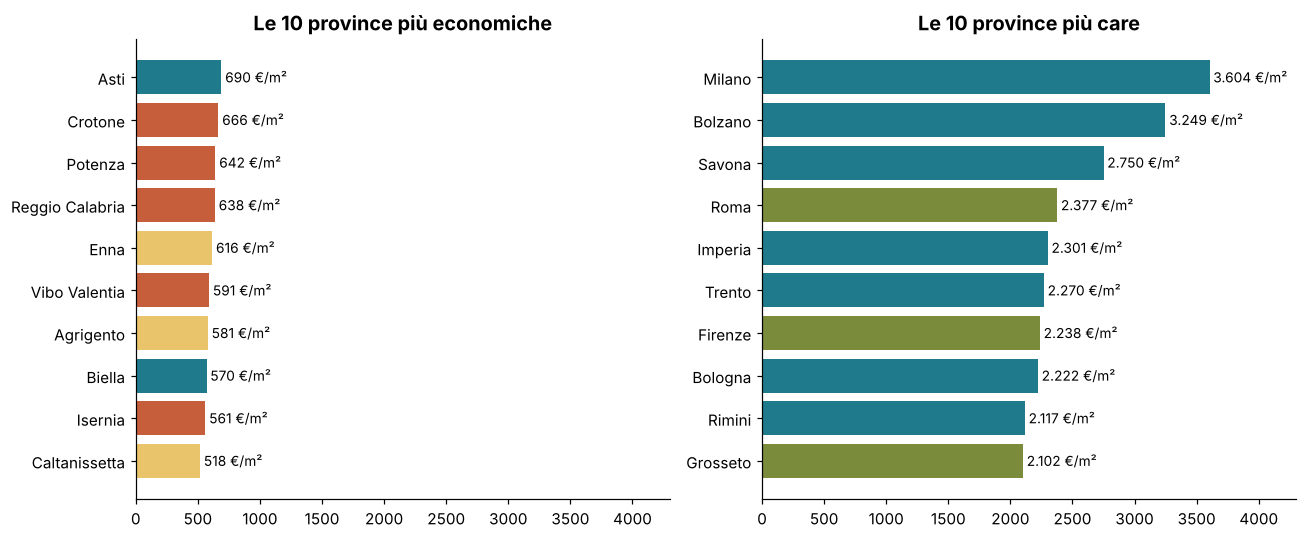

zona
Sud        802.0
Isole      831.0
Nord      1323.0
Centro    1422.0
Name: prezzo_casa_mq, dtype: float64


In [4]:
o = p.dropna(subset=["prezzo_casa_mq"]).sort_values("prezzo_casa_mq")
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharex=True)
for a, d, tit in [(ax[0], o.head(10), "Le 10 province più economiche"), (ax[1], o.tail(10), "Le 10 province più care")]:
    a.barh(d["provincia"], d["prezzo_casa_mq"], color=[ZONE[z] for z in d["zona"]])
    for y, v in enumerate(d["prezzo_casa_mq"]): a.text(v + 30, y, f"{v:,.0f} €/m²".replace(",", "."), va="center", fontsize=9)
    a.set_title(tit); a.set_xlim(0, 4300)
salva("03_prezzo_case")
print(p.groupby("zona").prezzo_casa_mq.median().round(0).sort_values())

## 3️⃣ ⚖️ Quanti anni di reddito per una casa?

📌 **Anni di reddito** = prezzo di una casa da **80 m²** diviso il reddito medio di un anno.
È un indicatore semplice: non tiene conto di mutuo, tasse e spese.

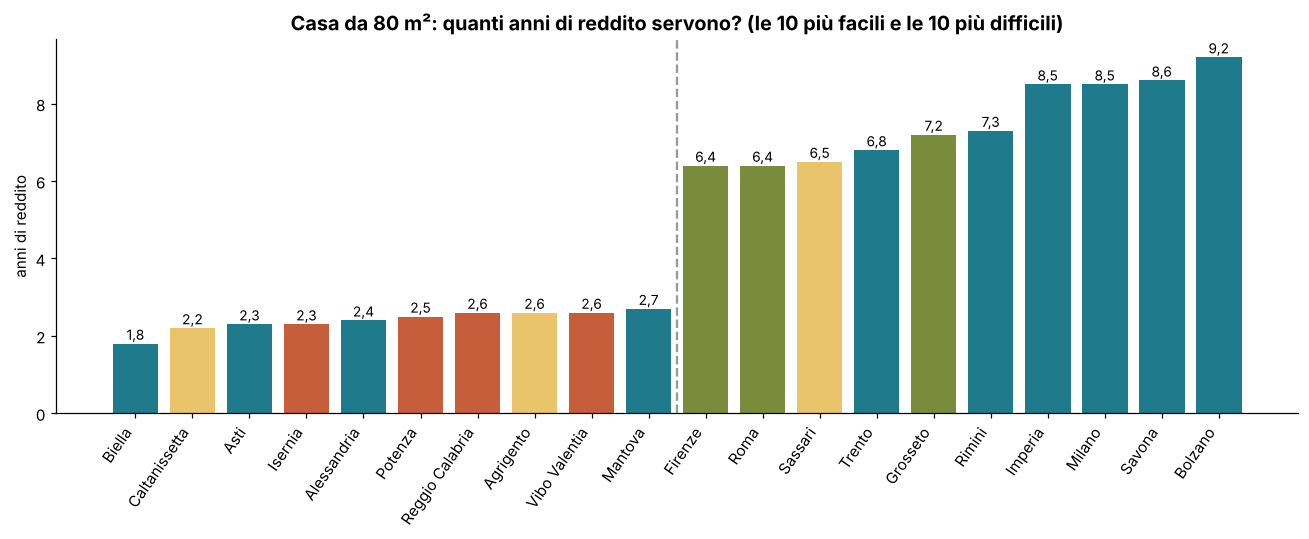

Mediana: 3.8499999999999996 anni


In [5]:
o = p.dropna(subset=["anni_reddito_casa"]).sort_values("anni_reddito_casa")
fig, ax = plt.subplots(figsize=(12, 5))
d = pd.concat([o.head(10), o.tail(10)])
ax.bar(d["provincia"], d["anni_reddito_casa"], color=[ZONE[z] for z in d["zona"]])
for x, v in enumerate(d["anni_reddito_casa"]): ax.text(x, v + 0.1, f"{v:.1f}".replace(".", ","), ha="center", fontsize=9)
ax.axvline(9.5, color="#999", ls="--"); ax.set_ylabel("anni di reddito")
ax.set_title("Casa da 80 m²: quanti anni di reddito servono? (le 10 più facili e le 10 più difficili)")
plt.xticks(rotation=55, ha="right"); salva("04_anni_reddito_casa")
print("Mediana:", o.anni_reddito_casa.median(), "anni")

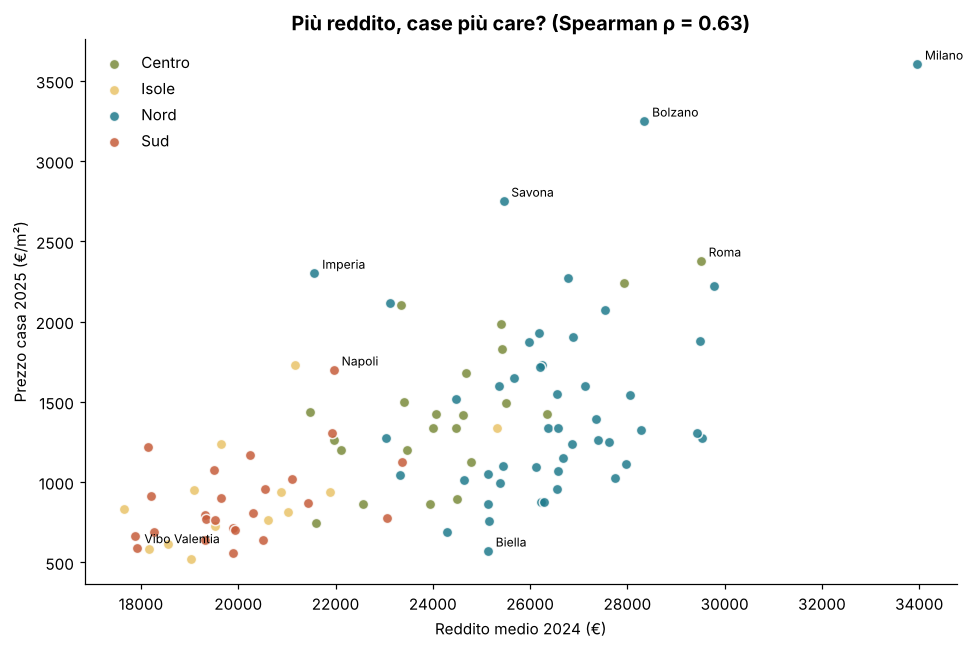

Correlazione di Spearman: rho = 0.63, p = 7.2e-13


In [6]:
# reddito e prezzo delle case vanno insieme?
d = p.dropna(subset=["prezzo_casa_mq"])
rho, pval = stats.spearmanr(d["reddito_medio"], d["prezzo_casa_mq"])
fig, ax = plt.subplots(figsize=(9, 6))
for z, g in d.groupby("zona"):
    ax.scatter(g["reddito_medio"], g["prezzo_casa_mq"], color=ZONE[z], label=z, s=45, alpha=0.85, edgecolor="white")
for sig in ["MI", "RM", "SV", "IM", "NA", "BI", "BZ", "VV"]:
    r = d[d.sigla == sig].iloc[0]; ax.annotate(r.provincia, (r.reddito_medio, r.prezzo_casa_mq), xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("Reddito medio 2024 (€)"); ax.set_ylabel("Prezzo casa 2025 (€/m²)"); ax.legend(frameon=False)
ax.set_title(f"Più reddito, case più care? (Spearman ρ = {rho:.2f})"); salva("05_reddito_vs_case")
print(f"Correlazione di Spearman: rho = {rho:.2f}, p = {pval:.1e}")

## 4️⃣ 📈 Come sono cambiati redditi e case (2016-2024)?

📌 Valori **nominali** (senza togliere l'inflazione).
L'inflazione in Italia dal 2017 al 2024 ha fatto salire i prezzi di circa il **21%** (ISTAT, indice NIC).

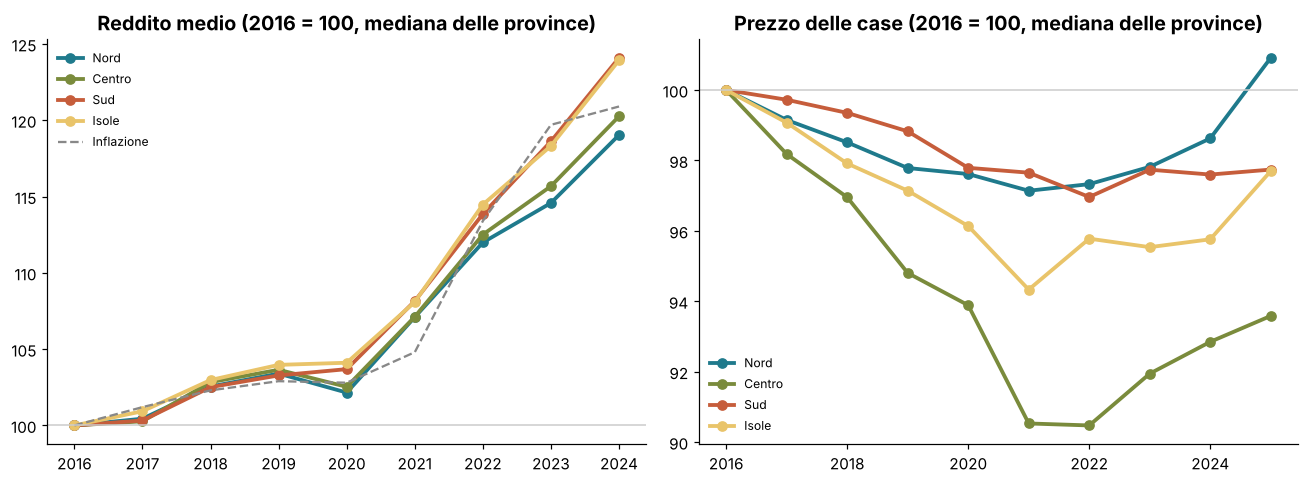

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
# solo le province con tutti gli anni (così il gruppo non cambia da un anno all'altro); Sardegna esclusa dai redditi
wr = redditi[~redditi.sigla.isin(["CA", "SS", "NU", "OR", "SU"])].pivot(index="sigla", columns="anno", values="reddito_medio").dropna()
wc = case.pivot(index="sigla", columns="anno", values="prezzo_mq").dropna()
zona = p.set_index("sigla").zona
for z, c in ZONE.items():
    g = (wr.div(wr[2016], axis=0) * 100)[zona.reindex(wr.index) == z].median()
    ax[0].plot(g.index, g, color=c, lw=2.5, marker="o", label=z)
    h = (wc.div(wc[2016], axis=0) * 100)[zona.reindex(wc.index) == z].median()
    ax[1].plot(h.index, h, color=c, lw=2.5, marker="o", label=z)
infl = pd.Series([100, 101.2, 102.3, 102.9, 102.8, 104.8, 113.4, 119.7, 120.9], index=range(2016, 2025))
ax[0].plot(infl.index, infl, color="#888", ls="--", label="Inflazione")
ax[0].set_title("Reddito medio (2016 = 100, mediana delle province)"); ax[1].set_title("Prezzo delle case (2016 = 100, mediana delle province)")
for a in ax: a.axhline(100, color="#ccc", lw=1); a.legend(frameon=False, fontsize=8)
salva("06_andamento_redditi_case")

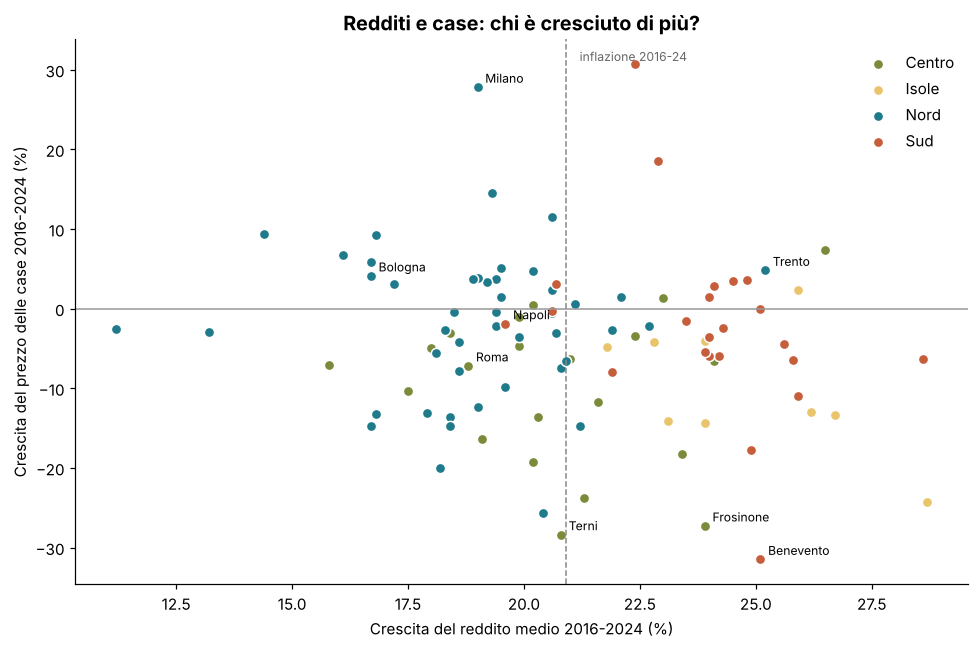

Redditi +20.6% · Case -3.6% (mediane)
Case salite più dei redditi: 2 province su 100


In [8]:
d = p.dropna(subset=["crescita_reddito_pct", "crescita_casa_pct"])
fig, ax = plt.subplots(figsize=(9, 6))
for z, g in d.groupby("zona"):
    ax.scatter(g["crescita_reddito_pct"], g["crescita_casa_pct"], color=ZONE[z], label=z, s=45, edgecolor="white")
ax.axhline(0, color="#999", lw=1); ax.axvline(20.9, color="#888", ls="--", lw=1)
ax.text(21.2, ax.get_ylim()[1] * 0.92, "inflazione 2016-24", color="#666", fontsize=8)
for sig in ["MI", "BO", "TN", "FR", "TR", "BN", "RM", "NA"]:
    r = d[d.sigla == sig].iloc[0]; ax.annotate(r.provincia, (r.crescita_reddito_pct, r.crescita_casa_pct), xytext=(5, 3), textcoords="offset points", fontsize=8)
ax.set_xlabel("Crescita del reddito medio 2016-2024 (%)"); ax.set_ylabel("Crescita del prezzo delle case 2016-2024 (%)")
ax.legend(frameon=False); ax.set_title("Redditi e case: chi è cresciuto di più?"); salva("07_crescita_redditi_case")
print(f"Redditi +{d.crescita_reddito_pct.median():.1f}% · Case {d.crescita_casa_pct.median():+.1f}% (mediane)")
print("Case salite più dei redditi:", (d.crescita_casa_pct > d.crescita_reddito_pct).sum(), "province su", len(d))

## 5️⃣ ⛽ Quanto pesa un pieno?

📌 Pieno da **50 litri** di benzina self (15 ottobre 2026) diviso il reddito medio di un mese.

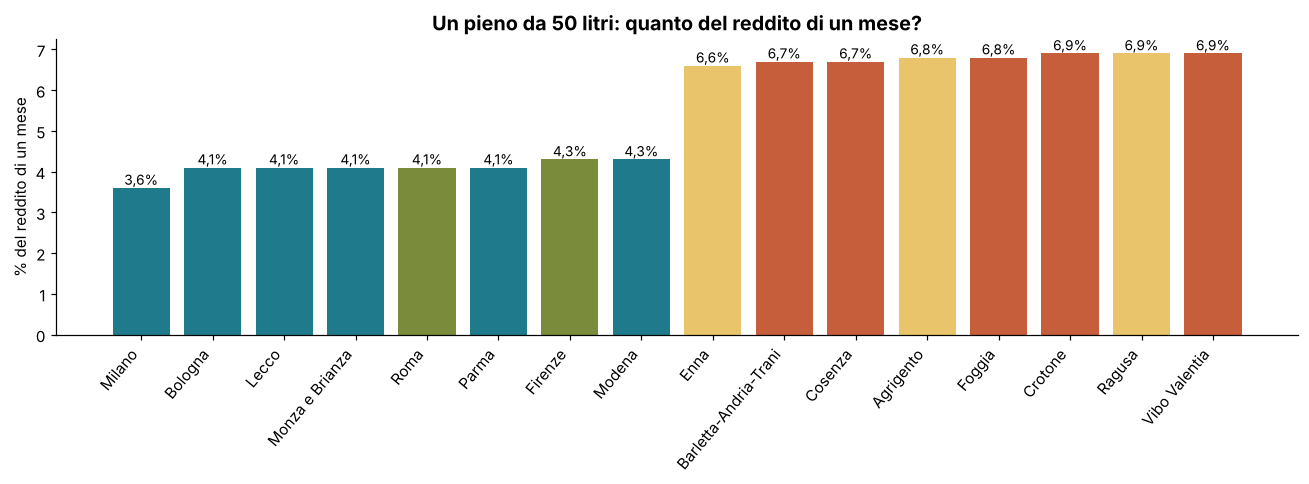

zona
Nord      4.60
Centro    5.05
Isole     6.25
Sud       6.25
Name: pieno_pct_reddito_mese, dtype: float64


In [9]:
o = p.sort_values("pieno_pct_reddito_mese")
fig, ax = plt.subplots(figsize=(12, 4.5))
d = pd.concat([o.head(8), o.tail(8)])
ax.bar(d["provincia"], d["pieno_pct_reddito_mese"], color=[ZONE[z] for z in d["zona"]])
for x, v in enumerate(d["pieno_pct_reddito_mese"]): ax.text(x, v + 0.08, f"{v:.1f}%".replace(".", ","), ha="center", fontsize=9)
ax.set_ylabel("% del reddito di un mese"); ax.set_title("Un pieno da 50 litri: quanto del reddito di un mese?")
plt.xticks(rotation=50, ha="right"); salva("08_pieno_reddito")
print(p.groupby("zona").pieno_pct_reddito_mese.median().sort_values())

## 💶 Bonus: come sono divisi i redditi?

📌 Percentuale di contribuenti per fascia di reddito, Nord contro Sud e Isole (2024).

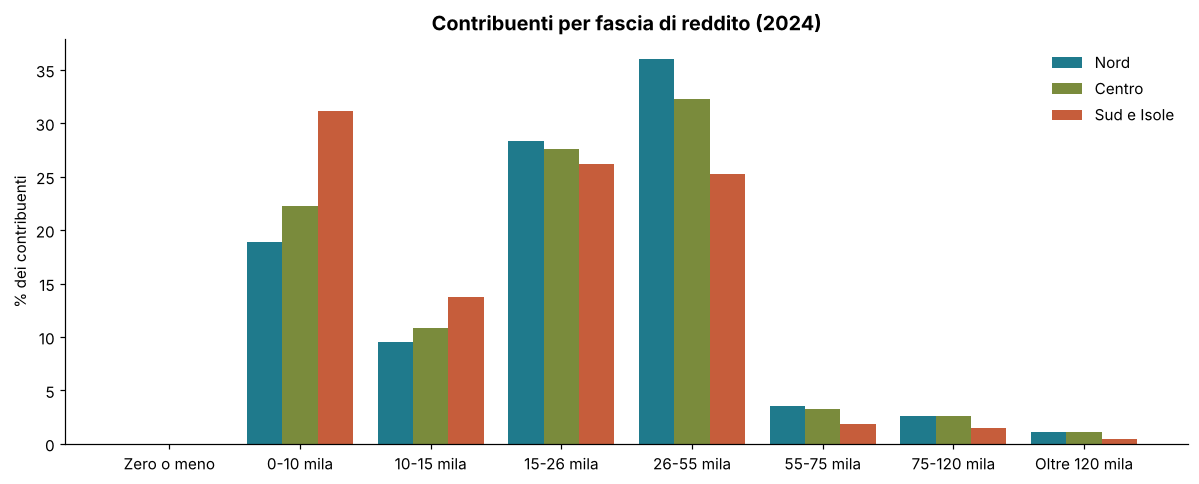

 n_fascia         fascia  Centro  Nord  Sud e Isole
        1    Zero o meno     0.0   0.0          0.0
        2      0-10 mila    22.3  18.9         31.1
        3     10-15 mila    10.9   9.5         13.8
        4     15-26 mila    27.6  28.3         26.2
        5     26-55 mila    32.3  36.0         25.2
        6     55-75 mila     3.3   3.6          1.8
        7    75-120 mila     2.6   2.6          1.5
        8 Oltre 120 mila     1.1   1.1          0.4


In [10]:
f = fasce.assign(gruppo=np.where(fasce.zona.isin(["Sud", "Isole"]), "Sud e Isole", np.where(fasce.zona == "Nord", "Nord", "Centro")))
t = f.groupby(["gruppo", "n_fascia", "fascia"]).n_contribuenti.sum().reset_index()
t["pct"] = t.n_contribuenti / t.groupby("gruppo").n_contribuenti.transform("sum") * 100
w = t.pivot(index=["n_fascia", "fascia"], columns="gruppo", values="pct").reset_index().sort_values("n_fascia")
x = np.arange(len(w)); fig, ax = plt.subplots(figsize=(11, 4.5))
for i, (g, c) in enumerate([("Nord", PETROLIO), ("Centro", OLIVA), ("Sud e Isole", TERRA)]):
    ax.bar(x + (i - 1) * 0.27, w[g], 0.27, color=c, label=g)
ax.set_xticks(x, w["fascia"]); ax.set_ylabel("% dei contribuenti"); ax.legend(frameon=False)
ax.set_title("Contribuenti per fascia di reddito (2024)"); salva("09_fasce_reddito")
print(w.round(1).to_string(index=False))

## 🏆 La classifica finale

📌 **Indice del costo della vita** (da 0 a 100): mette insieme gli anni di reddito per la casa (70%)
e il peso del pieno sul reddito (30%). Più è basso, più lo stipendio "rende".

In [11]:
cols = ["posizione", "provincia", "zona", "reddito_medio", "prezzo_casa_mq", "anni_reddito_casa", "pieno_pct_reddito_mese", "indice_costo"]
o = p.dropna(subset=["indice_costo"]).sort_values("indice_costo")
print("🟢 Dove lo stipendio rende di più"); display(o[cols].head(10))
print("🔴 Dove lo stipendio rende di meno"); display(o[cols].tail(10))

🟢 Dove lo stipendio rende di più


,posizione,provincia,zona,reddito_medio,prezzo_casa_mq,anni_reddito_casa,pieno_pct_reddito_mese,indice_costo
11,1.0,Biella,Nord,25135.0,570.0,1.8,4.8,12.0
1,2.0,Alessandria,Nord,25157.0,756.0,2.4,4.8,15.0
53,2.0,Mantova,Nord,26226.0,877.0,2.7,4.6,15.0
67,2.0,Pordenone,Nord,26291.0,877.0,2.7,4.6,15.0
62,5.0,Piacenza,Nord,27755.0,1023.0,2.9,4.4,16.0
7,6.0,Asti,Nord,24299.0,690.0,2.3,5.0,17.0
26,7.0,Cremona,Nord,26546.0,957.0,2.9,4.6,20.0
101,8.0,Vercelli,Nord,25132.0,866.0,2.8,4.8,21.0
76,9.0,Reggio Emilia,Nord,27963.0,1114.0,3.2,4.3,24.0
5,10.0,L'Aquila,Sud,23049.0,777.0,2.7,5.3,26.0


🔴 Dove lo stipendio rende di meno


,posizione,provincia,zona,reddito_medio,prezzo_casa_mq,anni_reddito_casa,pieno_pct_reddito_mese,indice_costo
45,97.0,Livorno,Centro,25408.0,1987.0,6.3,4.8,75.0
59,98.0,Nuoro,Isole,19642.0,1235.0,5.0,6.3,78.0
47,98.0,Latina,Centro,21481.0,1436.0,5.3,5.7,78.0
89,100.0,Savona,Nord,25456.0,2750.0,8.6,4.8,81.0
57,101.0,Napoli,Sud,21968.0,1698.0,6.2,5.6,83.0
80,102.0,Rimini,Nord,23118.0,2117.0,7.3,5.3,85.0
39,102.0,Grosseto,Centro,23344.0,2102.0,7.2,5.3,85.0
17,104.0,Barletta-Andria-Trani,Sud,18139.0,1217.0,5.4,6.7,86.0
87,105.0,Sassari,Isole,21169.0,1727.0,6.5,5.8,87.0
40,106.0,Imperia,Nord,21568.0,2301.0,8.5,5.6,89.0


## ✅ Conclusioni

Le risposte complete sono nel file **CONCLUSIONI.md**.

⚠️ **Limiti**: redditi lordi e medi (non mediani); prezzi delle case medi per tutta la provincia;
nessun dato sugli affitti; il carburante è di un solo giorno; Sardegna con province cambiate nel 2016-2019.